# Лабораторная работа №2. Семантическая сегментация

6233 Саленая Юлия


## 1. Теория

**Классификация** даёт метку всему изображению. **Детекция** находит объекты и описывает их прямоугольниками. **Семантическая сегментация** присваивает класс каждому пикселю. Два объекта одного класса получают одинаковую метку.

В **U-Net** энкодер уменьшает разрешение и извлекает признаки. Декодер восстанавливает разрешение, а skip connections передают ему признаки с соответствующих уровней энкодера. Они помогают сохранить мелкие детали и границы. Здесь реализуем компактный вариант с тремя уровнями уменьшения разрешения.

**DeepLabv3+** применяет свёртки с расширением (dilated, или atrous convolutions). Например, при dilation=2 ядро берёт значения через один пиксель и охватывает большую область с тем же числом весов. ASPP объединяет контекст нескольких масштабов, а декодер уточняет границы.

Для класса сравнивается множество предсказанных пикселей $P$ с истинным множеством $G$:

$$IoU=\frac{|P\cap G|}{|P\cup G|},\qquad Dice=\frac{2|P\cap G|}{|P|+|G|}.$$

Обе метрики лежат в диапазоне от 0 до 1. Сначала суммируются пиксельные ошибки по всей выборке, затем считаются метрики каждого класса. Для сравнения используется **mIoU и macro Dice** — средние по классам объектов, присутствующим в разметке.

## 2. Данные и подготовка масок



In [1]:
from pathlib import Path
import random
import shutil

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from torch import nn
from torch.utils.data import DataLoader, Dataset
from torchvision.datasets import VOCSegmentation
from torchvision.transforms import ColorJitter
from torchvision.transforms.functional import hflip, to_tensor
from IPython.display import display

SEED = 42
SIZE, BATCH, EPOCHS = 128, 16, 15
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
DATA = Path('/content/voc_data')
OUT = Path('/content/lab2_results')
DATA.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)
NAMES = ['background', 'aeroplane', 'bicycle', 'bird', 'boat', 'bottle',
         'bus', 'car', 'cat', 'chair', 'cow', 'diningtable', 'dog', 'horse',
         'motorbike', 'person', 'pottedplant', 'sheep', 'sofa', 'train', 'tvmonitor']
N_CLASSES = len(NAMES)
print('Устройство', DEVICE, '| PyTorch', torch.__version__)

ready = DATA / 'VOCdevkit/VOC2012/ImageSets/Segmentation/val.txt'
voc_train = VOCSegmentation(DATA, year='2012', image_set='train', download=not ready.exists())
voc_val = VOCSegmentation(DATA, year='2012', image_set='val')
rng = random.Random(SEED)
train_ids = rng.sample(range(len(voc_train)), 1000)
held_out = rng.sample(range(len(voc_val)), 512)
val_ids, test_ids = held_out[:256], held_out[256:]
assert set(val_ids).isdisjoint(test_ids)
print('Train / validation / test:', len(train_ids), len(val_ids), len(test_ids))

Successfully renamed PrivateUse1 backend to 'tpu'. Device: device(type='tpu')
Registered Python module for 'tpu'.
Device type: tpu, Device index: default
Initializing TPU distributed runtime


Устройство cpu | PyTorch 2.14.1+cpu


100%|██████████| 2.00G/2.00G [01:11<00:00, 28.1MB/s]


Train / validation / test: 1000 256 256


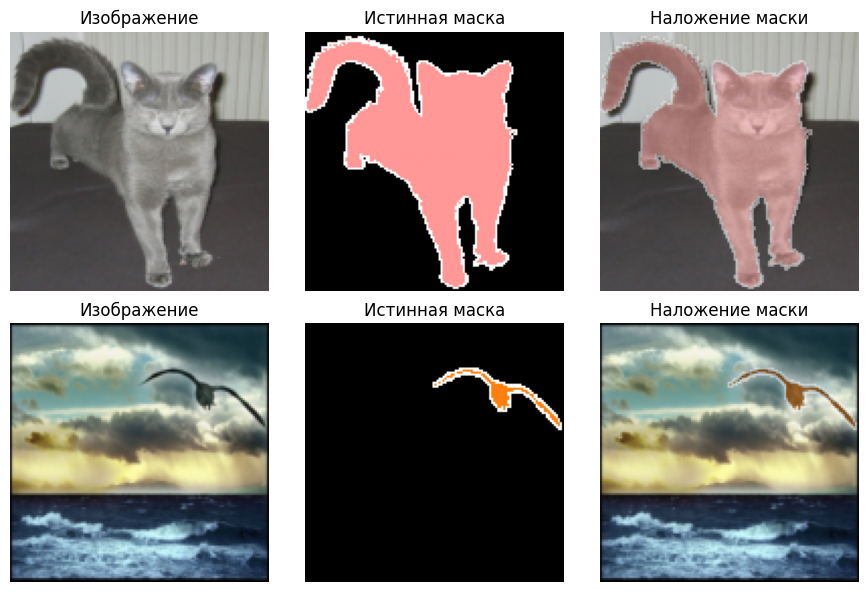

In [2]:
class SegmentationSubset(Dataset):
    def __init__(self, dataset, indices, augment=False):
        self.dataset = dataset
        self.indices = indices
        self.augment = augment
        self.jitter = ColorJitter(brightness=0.2, contrast=0.2)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        rgb, mask = self.dataset[self.indices[index]]
        rgb = rgb.resize((SIZE, SIZE), Image.Resampling.BILINEAR)
        mask = mask.resize((SIZE, SIZE), Image.Resampling.NEAREST)
        if self.augment:
            if random.random() < 0.5:
                rgb, mask = hflip(rgb), hflip(mask)
            rgb = self.jitter(rgb)
        return to_tensor(rgb), torch.from_numpy(np.array(mask, dtype=np.int64))

train_plain = SegmentationSubset(voc_train, train_ids)
val_data = SegmentationSubset(voc_val, val_ids)
test_data = SegmentationSubset(voc_val, test_ids)
val_loader = DataLoader(val_data, batch_size=BATCH, num_workers=2)
test_loader = DataLoader(test_data, batch_size=BATCH, num_workers=2)

# цвета постоянны для всех рисунков
COLORS = np.zeros((256, 3))
COLORS[1:N_CLASSES] = plt.get_cmap('tab20').colors
COLORS[255] = 1

def overlay(rgb, mask):
    result = rgb.copy()
    foreground = mask > 0
    result[foreground] = 0.55 * rgb[foreground] + 0.45 * COLORS[mask[foreground]]
    return result

fig, axes = plt.subplots(2, 3, figsize=(9, 6))
for i, row in enumerate(axes):
    x, y = train_plain[i]
    rgb, mask = x.permute(1, 2, 0).numpy(), y.numpy()
    for ax, panel, title in zip(row, [rgb, COLORS[mask], overlay(rgb, mask)],
                                ['Изображение', 'Истинная маска', 'Наложение маски']):
        ax.imshow(panel)
        ax.set_title(title)
        ax.axis('off')
fig.tight_layout()
fig.savefig(OUT / 'dataset_examples.png', dpi=150)
plt.show()

## 3. U-Net



In [3]:
def conv_block(in_channels, out_channels):
    return nn.Sequential(
        nn.Conv2d(in_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels), nn.ReLU(),
        nn.Conv2d(out_channels, out_channels, 3, padding=1, bias=False),
        nn.BatchNorm2d(out_channels), nn.ReLU(),
    )

class UNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.enc1 = conv_block(3, 16)
        self.enc2 = conv_block(16, 32)
        self.enc3 = conv_block(32, 64)
        self.pool = nn.MaxPool2d(2)
        self.center = conv_block(64, 128)
        self.up3 = nn.ConvTranspose2d(128, 64, 2, stride=2)
        self.up2 = nn.ConvTranspose2d(64, 32, 2, stride=2)
        self.up1 = nn.ConvTranspose2d(32, 16, 2, stride=2)
        self.dec3 = conv_block(128, 64)
        self.dec2 = conv_block(64, 32)
        self.dec1 = conv_block(32, 16)
        self.head = nn.Conv2d(16, N_CLASSES, 1)

    def forward(self, x):
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        z = self.center(self.pool(e3))
        d3 = self.dec3(torch.cat([self.up3(z), e3], dim=1))
        d2 = self.dec2(torch.cat([self.up2(d3), e2], dim=1))
        d1 = self.dec1(torch.cat([self.up1(d2), e1], dim=1))
        return self.head(d1)

criterion = nn.CrossEntropyLoss(ignore_index=255)

## 4. Оценка и обучение

Строка матрицы ошибок — истинный класс, столбец — предсказанный. Диагональ даёт пересечения. Сумма строки — число истинных пикселей класса, сумма столбца — число предсказанных.

**A:** только изменение размера. **B:** дополнительно случайное горизонтальное отражение изображения и маски вместе, а также изменение яркости и контраста изображения. Начальные веса, порядок батчей, оптимизатор, размер входа и число эпох одинаковы. Сохраняем лучшую эпоху каждого варианта по mIoU на validation.

In [4]:
@torch.inference_mode()
def evaluate(model, loader):
    model.eval()
    matrix = torch.zeros((N_CLASSES, N_CLASSES), dtype=torch.int64)
    for x, y in loader:
        pred = model(x.to(DEVICE)).argmax(dim=1).cpu()
        valid = y != 255
        pairs = N_CLASSES * y[valid] + pred[valid]
        matrix += torch.bincount(pairs, minlength=N_CLASSES**2).reshape(N_CLASSES, N_CLASSES)

    intersection = matrix.diag().float()
    true_count = matrix.sum(dim=1)
    pred_count = matrix.sum(dim=0)
    total = true_count + pred_count
    iou = intersection / (total - intersection).clamp_min(1)
    dice = 2 * intersection / total.clamp_min(1)
    present = true_count > 0
    objects = present.clone()
    objects[0] = False
    return {
        'mIoU': iou[objects].mean().item(),
        'Dice': dice[objects].mean().item(),
        'accuracy': (intersection.sum() / matrix.sum()).item(),
        'IoU по классам': iou.masked_fill(~present, float('nan')).numpy(),
        'Dice по классам': dice.masked_fill(~present, float('nan')).numpy(),
        'Пиксели': true_count.numpy(),
    }

def train_experiment(name, augment):
    random.seed(SEED)
    torch.manual_seed(SEED)
    loader = DataLoader(
        SegmentationSubset(voc_train, train_ids, augment),
        batch_size=BATCH, shuffle=True, num_workers=2,
        generator=torch.Generator().manual_seed(SEED),
    )
    model = UNet().to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameters(), lr=0.001)
    best_iou = -1.0
    checkpoint = OUT / f'unet_{name}.pt'
    history = []
    for epoch in range(1, EPOCHS + 1):
        model.train()
        loss_sum = 0.0
        for x, y in loader:
            optimizer.zero_grad()
            loss = criterion(model(x.to(DEVICE)), y.to(DEVICE))
            loss.backward()
            optimizer.step()
            loss_sum += loss.item()

        val = evaluate(model, val_loader)
        train_loss = loss_sum / len(loader)
        history.append({'epoch': epoch, 'train_loss': train_loss,
                        'val_mIoU': val['mIoU'], 'val_Dice': val['Dice']})
        if val['mIoU'] > best_iou:
            best_iou = val['mIoU']
            best_epoch = epoch
            torch.save(model.state_dict(), checkpoint)
        print(f'{name} | {epoch:02d}/{EPOCHS} | loss={train_loss:.4f} '
              f'| val mIoU={val["mIoU"]:.4f} | val Dice={val["Dice"]:.4f}')

    model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
    return model, pd.DataFrame(history), best_epoch

experiments = {
    'A': train_experiment('A', augment=False),
    'B': train_experiment('B', augment=True),
}

A | 01/15 | loss=2.7601 | val mIoU=0.0054 | val Dice=0.0103
A | 02/15 | loss=2.1288 | val mIoU=0.0062 | val Dice=0.0112
A | 03/15 | loss=1.5884 | val mIoU=0.0057 | val Dice=0.0104
A | 04/15 | loss=1.3081 | val mIoU=0.0058 | val Dice=0.0105
A | 05/15 | loss=1.2228 | val mIoU=0.0000 | val Dice=0.0000
A | 06/15 | loss=1.1999 | val mIoU=0.0003 | val Dice=0.0005
A | 07/15 | loss=1.1792 | val mIoU=0.0046 | val Dice=0.0084
A | 08/15 | loss=1.1743 | val mIoU=0.0002 | val Dice=0.0004
A | 09/15 | loss=1.1629 | val mIoU=0.0000 | val Dice=0.0001
A | 10/15 | loss=1.1429 | val mIoU=0.0071 | val Dice=0.0125
A | 11/15 | loss=1.1401 | val mIoU=0.0048 | val Dice=0.0091
A | 12/15 | loss=1.1249 | val mIoU=0.0033 | val Dice=0.0064
A | 13/15 | loss=1.1127 | val mIoU=0.0032 | val Dice=0.0062
A | 14/15 | loss=1.0971 | val mIoU=0.0129 | val Dice=0.0228
A | 15/15 | loss=1.0892 | val mIoU=0.0131 | val Dice=0.0233
B | 01/15 | loss=2.7623 | val mIoU=0.0015 | val Dice=0.0030
B | 02/15 | loss=2.1572 | val mIoU=0.001

## 5. Сравнение на тестовой выборке

Accuracy здесь показана для сопоставления с основными метриками. `NaN` в таблице по классам означает, что класс отсутствует в истинных масках test. Графики справа показывают качество на validation по эпохам.

,Аугментации,Лучшая эпоха,mIoU,Dice,accuracy
Вариант,,,,,
A,нет,15,0.0121,0.0218,0.7479
B,да,15,0.0097,0.0177,0.7538


,Класс,Пиксели,IoU A,Dice A,IoU B,Dice B
0,background,2960700,0.7767,0.8743,0.7624,0.8652
1,aeroplane,25221,0.0000,0.0000,0.0000,0.0000
2,bicycle,11117,0.0000,0.0000,0.0000,0.0000
3,bird,24479,0.0000,0.0000,0.0000,0.0000
4,boat,32478,0.0000,0.0000,0.0000,0.0000
5,bottle,35532,0.0000,0.0000,0.0000,0.0000
6,bus,31842,0.0143,0.0283,0.0590,0.1114
7,car,34864,0.0005,0.0010,0.0121,0.0239
8,cat,85977,0.0931,0.1703,0.0002,0.0005
9,chair,41564,0.0000,0.0000,0.0000,0.0000


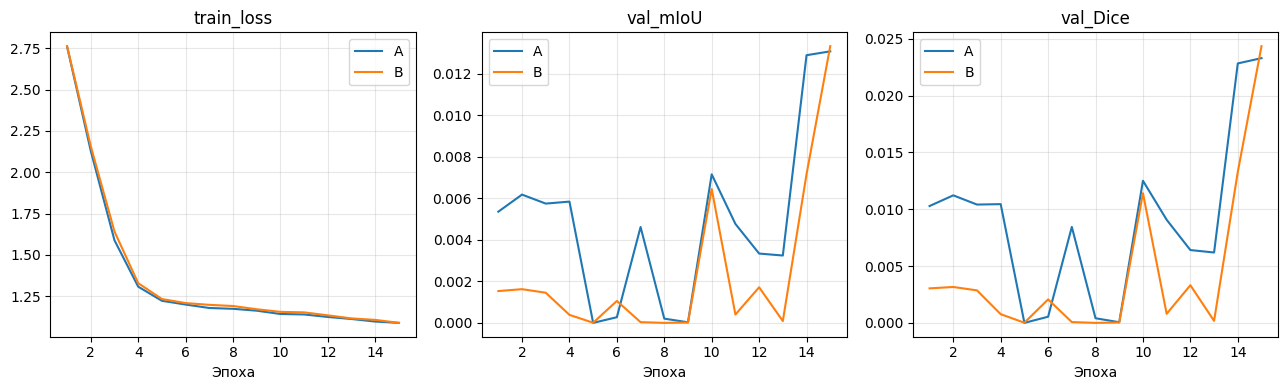

mIoU: 0.0121 → 0.0097, разница B − A: -0.25 п.п.
Dice: 0.0218 → 0.0177, разница B − A: -0.41 п.п.


In [5]:
test_metrics = {name: evaluate(run[0], test_loader) for name, run in experiments.items()}
summary = pd.DataFrame([
    {'Вариант': name, 'Аугментации': 'да' if name == 'B' else 'нет',
     'Лучшая эпоха': run[2],
     **{key: test_metrics[name][key] for key in ['mIoU', 'Dice', 'accuracy']}}
    for name, run in experiments.items()
]).set_index('Вариант')
classes = pd.DataFrame({'Класс': NAMES, 'Пиксели': test_metrics['A']['Пиксели']})
for name, result in test_metrics.items():
    classes[f'IoU {name}'] = result['IoU по классам']
    classes[f'Dice {name}'] = result['Dice по классам']
display(summary.round(4))
display(classes.round(4))
summary.to_csv(OUT / 'test_summary.csv')
classes.to_csv(OUT / 'test_per_class.csv', index=False)

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for name, (_, history, _) in experiments.items():
    history.to_csv(OUT / f'history_{name}.csv', index=False)
    for ax, col in zip(axes, ['train_loss', 'val_mIoU', 'val_Dice']):
        ax.plot(history['epoch'], history[col], label=name)
        ax.set(xlabel='Эпоха', title=col)
        ax.grid(alpha=0.3)
        ax.legend()
fig.tight_layout()
fig.savefig(OUT / 'training_curves.png', dpi=150)
plt.show()

for metric in ['mIoU', 'Dice']:
    a, b = summary.loc['A', metric], summary.loc['B', metric]
    print(f'{metric}: {a:.4f} → {b:.4f}, разница B − A: {(b-a)*100:+.2f} п.п.')

## 6. Предсказания на одинаковых изображениях

Для каждого изображения отдельно показаны истинная маска, предсказанная маска A и предсказанная маска B. Цветные области обозначают классы объектов, чёрный цвет — фон, белый — игнорируемые пиксели (255).

Рядом с каждой предсказанной маской показано её наложение на фотографию. Цветная заливка и жёлтый контур выделяют предсказанные объекты. Одинаковым классам во всех колонках соответствуют одинаковые цвета. Легенда приведена под рисунком.


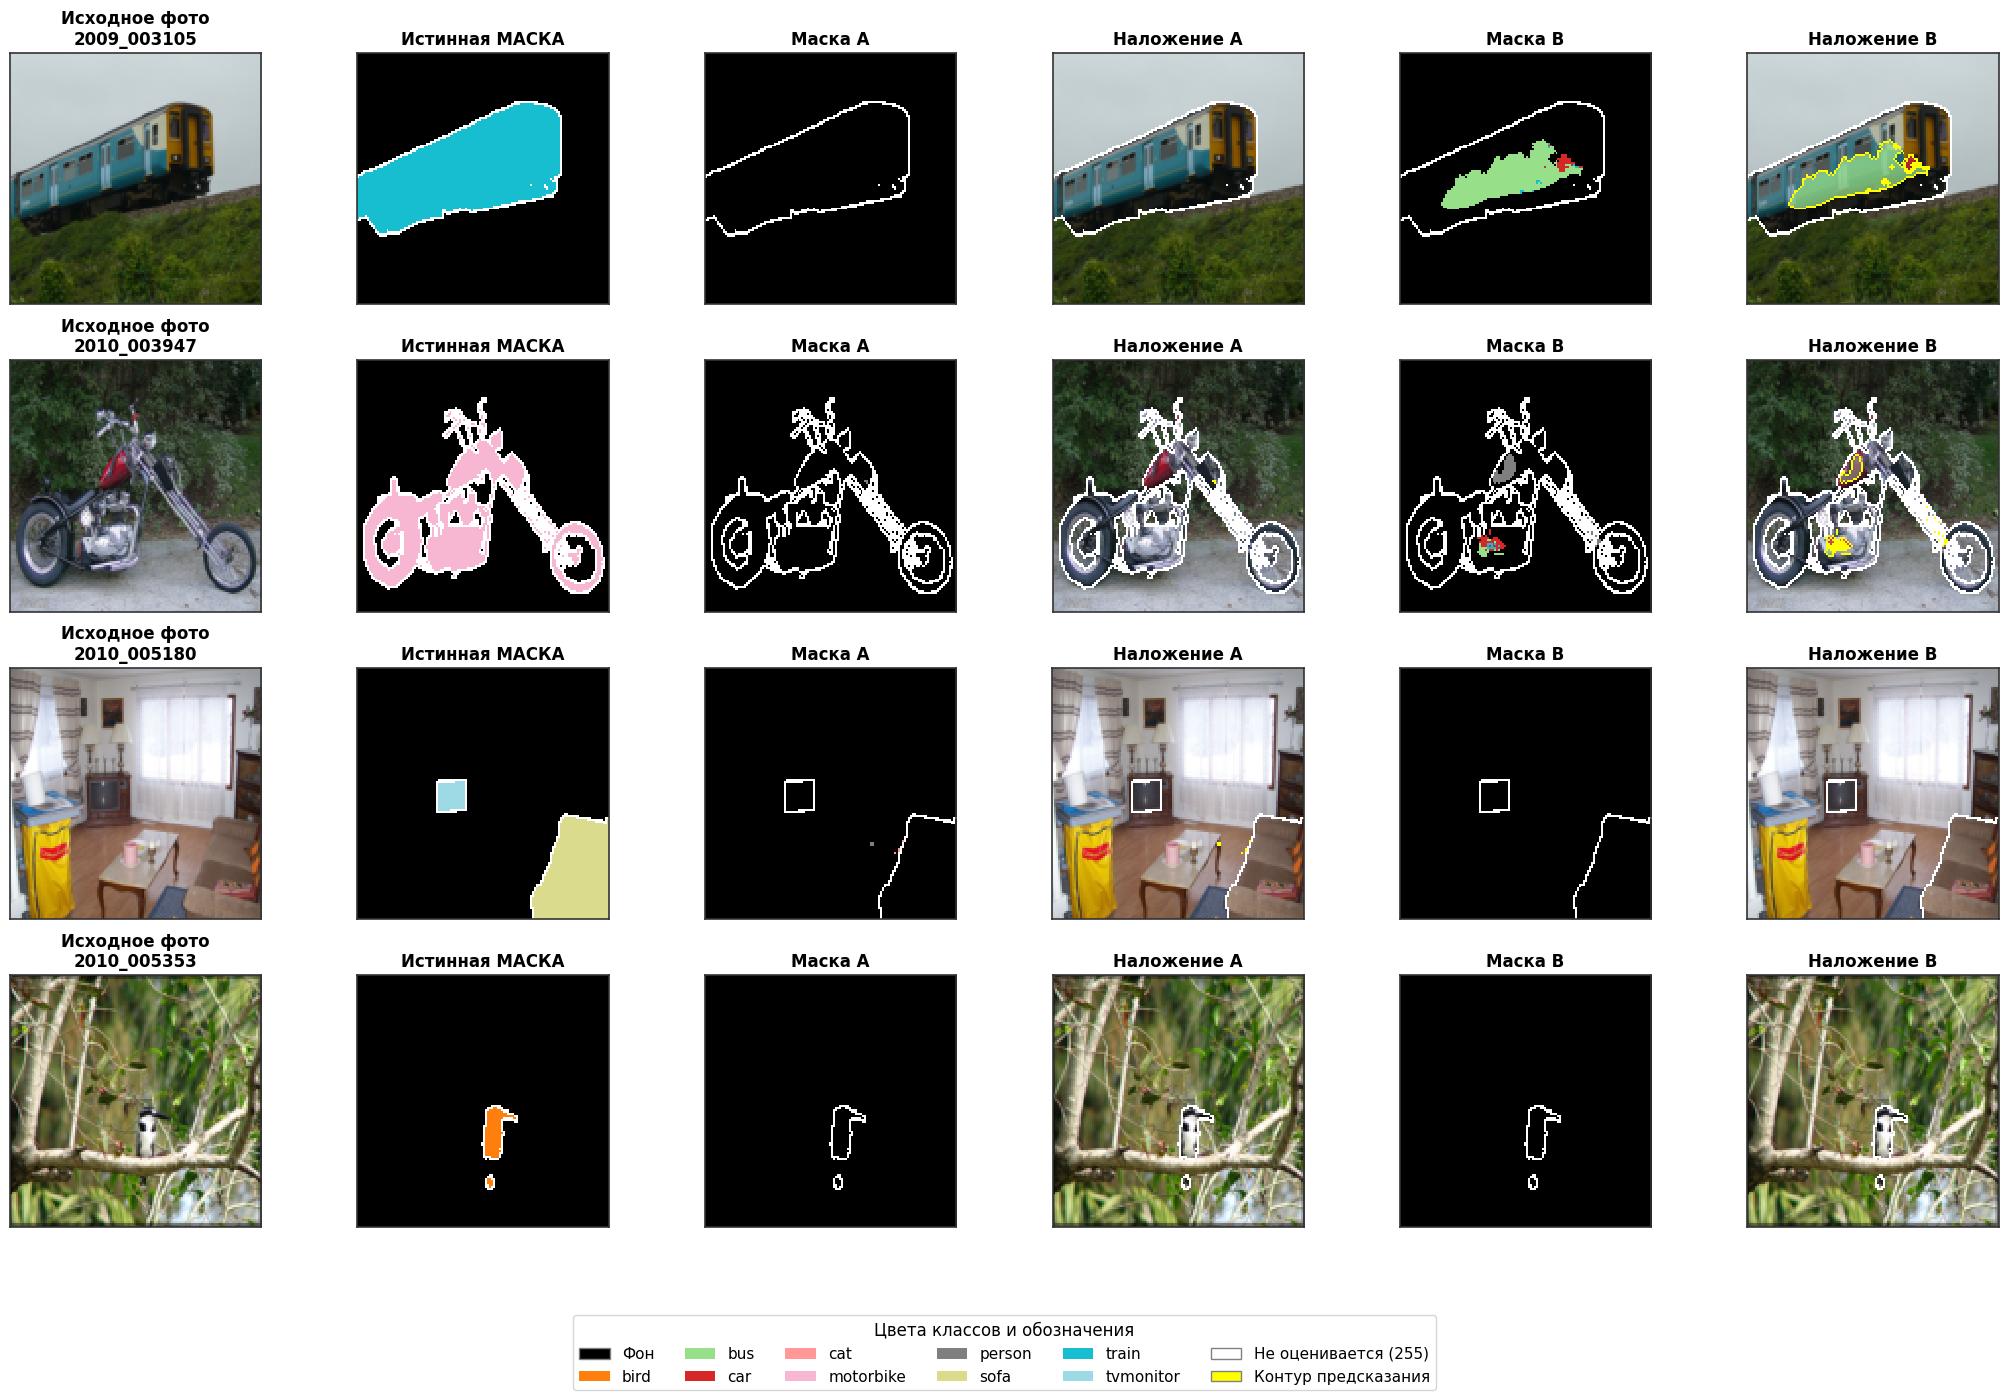

In [7]:
from matplotlib.patches import Patch

def overlay_with_outline(rgb, mask):
    result = rgb.copy()
    objects = (mask > 0) & (mask != 255)
    result[objects] = 0.25 * rgb[objects] + 0.75 * COLORS[mask[objects]]
    result[mask == 255] = 1.0

    boundary = np.zeros(mask.shape, dtype=bool)
    boundary[1:, :] |= mask[1:, :] != mask[:-1, :]
    boundary[:-1, :] |= mask[:-1, :] != mask[1:, :]
    boundary[:, 1:] |= mask[:, 1:] != mask[:, :-1]
    boundary[:, :-1] |= mask[:, :-1] != mask[:, 1:]
    result[boundary & objects] = [1.0, 1.0, 0.0]
    return result

titles = ['Исходное фото', 'Истинная МАСКА',
          'Маска A', 'Наложение A', 'Маска B', 'Наложение B']
fig, axes = plt.subplots(4, 6, figsize=(21, 14))
visible_classes = set()
with torch.inference_mode():
    for i, row in enumerate(axes):
        x, y = test_data[i]
        rgb, truth = x.permute(1, 2, 0).numpy(), y.numpy()
        panels = [rgb, COLORS[truth]]
        visible_classes.update(np.unique(truth).tolist())
        for name in ['A', 'B']:
            model = experiments[name][0]
            model.eval()
            pred = model(x[None].to(DEVICE)).argmax(1)[0].cpu().numpy()
            pred[truth == 255] = 255
            visible_classes.update(np.unique(pred).tolist())
            panels.extend([COLORS[pred], overlay_with_outline(rgb, pred)])

        image_id = Path(voc_val.images[test_ids[i]]).stem
        for col, (ax, panel) in enumerate(zip(row, panels)):
            ax.imshow(panel, interpolation='nearest')
            title = titles[col]
            if col == 0:
                title += '\n' + image_id
            ax.set_title(title, fontsize=12, fontweight='bold')
            ax.set_xticks([])
            ax.set_yticks([])
            for spine in ax.spines.values():
                spine.set_visible(True)
                spine.set_color('#333333')
                spine.set_linewidth(1.2)

handles = [Patch(facecolor='black', edgecolor='gray', label='Фон')]
handles += [Patch(facecolor=COLORS[c], label=NAMES[c])
            for c in sorted(visible_classes) if 0 < c < N_CLASSES]
handles += [Patch(facecolor='white', edgecolor='gray', label='Не оценивается (255)'),
            Patch(facecolor='yellow', edgecolor='gray', label='Контур предсказания')]
fig.legend(handles=handles, loc='lower center', ncol=6, fontsize=11,
           title='Цвета классов и обозначения', title_fontsize=12)
fig.tight_layout(rect=(0, 0.11, 1, 1))
fig.savefig(OUT / 'test_predictions.png', dpi=180, bbox_inches='tight')
plt.show()


## 7. Контрольные вопросы и вывод

**1. Почему accuracy плохо отражает качество сегментации?** При дисбалансе классов её определяют самые частые пиксели. Если фон занимает 95% изображения, предсказание «везде фон» даст accuracy 95%, но IoU и Dice для объекта будут равны 0. Усреднение по классам объектов помогает увидеть ошибки на редких категориях.

**2. Чем U-Net отличается от обычной CNN?** В обычной CNN для классификации карты признаков собираются в один вектор оценок для всего изображения. В U-Net декодер восстанавливает карту исходного разрешения, а skip connections добавляют пространственные детали с уровней энкодера. Выход содержит оценку класса для каждого пикселя.